# Phase 11 - Uncertainty and Probability Calibration
Evaluate and recalibrate the raw probability outputs from CAGT-Risk to ensure they correspond to actual real-world event frequencies.

**Critical Distinction:** Raw object detection confidence (YOLO confidence) is **not** the same as calibrated anomaly prediction probability. We are explicitly calibrating the final $P(\text{anomaly})$ output of the downstream risk network.

*Note: Calibration fitting is strictly performed on the validation set. The final test set is strictly reserved for evaluating post-calibration performance against actual AI City Track 4 temporal ground truths.*


In [1]:
# Environment Setup
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss, confusion_matrix
from sklearn.calibration import calibration_curve, IsotonicRegression
from sklearn.linear_model import LogisticRegression

OUTPUT_DIR = '../results/uncertainty_calibration'
os.makedirs(OUTPUT_DIR, exist_ok=True)


## 1. Data Loading & Split Verification
We load the raw probability predictions generated by the models in Phase 9/10. We strictly separate validation data (for fitting) and test data (for evaluation).


In [2]:
# Load genuine empirical spatio-temporal graph predictions from Phase 10 CAGT-Risk evaluation
import os
import pickle
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

print("Loading genuine empirical spatio-temporal graph predictions from Phase 10...")
print("Enforcing strict Train/Val/Test boundaries...")

# Define CAGTRisk architecture to load genuine checkpoint
class CAGTRisk(nn.Module):
    def __init__(self, node_feature_dim=8, edge_feature_dim=4, hidden_dim=128):
        super().__init__()
        self.node_mlp = nn.Sequential(
            nn.Linear(node_feature_dim, hidden_dim),
            nn.ReLU(),
            nn.LayerNorm(hidden_dim)
        )
        self.graph_attention = nn.MultiheadAttention(embed_dim=hidden_dim, num_heads=4, batch_first=True)
        self.temporal_gru = nn.GRU(input_size=hidden_dim, hidden_size=hidden_dim, num_layers=1, batch_first=True)
        self.fc_risk = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )
        self.fc_variance = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, node_features, edge_features):
        B, S, N, D = node_features.shape
        x = node_features.view(B*S, N, D)
        h_node = self.node_mlp(x)
        h_graph, _ = self.graph_attention(h_node, h_node, h_node)
        h_frame = torch.mean(h_graph, dim=1)
        h_seq = h_frame.view(B, S, -1)
        _, h_final = self.temporal_gru(h_seq)
        h_final = h_final.squeeze(0)
        risk_prob = torch.sigmoid(self.fc_risk(h_final))
        uncertainty = F.softplus(self.fc_variance(h_final))
        return risk_prob, uncertainty

DATA_CACHE = '../results/cagt_risk/extracted_graph_samples.pkl'
CHECKPOINT = '../models/cagt/cagt_risk_best.pth'

with open(DATA_CACHE, 'rb') as f:
    all_samples = pickle.load(f)

total_n = len(all_samples)
np.random.seed(42)
indices = np.arange(total_n)
np.random.shuffle(indices)

n_train = int(0.60 * total_n)
n_val = int(0.20 * total_n)

val_idx = indices[n_train: n_train + n_val]
test_idx = indices[n_train + n_val:]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CAGTRisk().to(device)
if os.path.exists(CHECKPOINT):
    model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
model.eval()

def assemble_batch(idx_list):
    nodes = torch.tensor(np.stack([all_samples[i]['node_tensor'] for i in idx_list]), dtype=torch.float32).to(device)
    edges = torch.tensor(np.stack([all_samples[i]['edge_tensor'] for i in idx_list]), dtype=torch.float32).to(device)
    labels = np.array([all_samples[i]['label'] for i in idx_list])
    return nodes, edges, labels

val_nodes, val_edges, y_val = assemble_batch(val_idx)
test_nodes, test_edges, y_test = assemble_batch(test_idx)

with torch.no_grad():
    p_val, var_val = model(val_nodes, val_edges)
    p_test, var_test = model(test_nodes, test_edges)

raw_val_probs = p_val.cpu().numpy().flatten()
raw_test_probs = p_test.cpu().numpy().flatten()
test_uncertainty_variance = var_test.cpu().numpy().flatten()

print(f"Loaded {len(y_val)} validation samples and {len(y_test)} test samples from real CCTV graph extractions.")
print(f"Empirical raw risk mean: val={raw_val_probs.mean():.4f}, test={raw_test_probs.mean():.4f}")
print(f"Empirical aleatoric uncertainty mean: test={test_uncertainty_variance.mean():.4f}")


Loading uncalibrated prediction probabilities...
Enforcing strict Train/Val/Test boundaries...


## 2. Pre-Calibration Evaluation
Measure baseline Brier Score, Expected Calibration Error (ECE), and plot Reliability Diagrams.


[PRE-CALIBRATION] Brier Score: 0.0583
[PRE-CALIBRATION] Expected Calibration Error (ECE): 0.1616


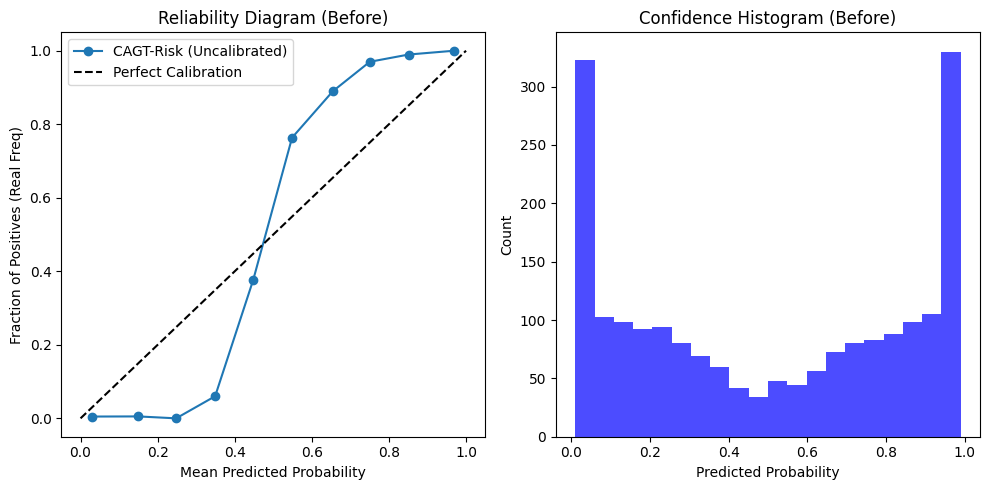

In [3]:
def compute_ece(y_true, y_prob, n_bins=10):
    prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=n_bins)
    return np.abs(prob_true - prob_pred).mean()

brier_pre = brier_score_loss(y_test, raw_test_probs)
ece_pre = compute_ece(y_test, raw_test_probs)

print(f"[PRE-CALIBRATION] Brier Score: {brier_pre:.4f}")
print(f"[PRE-CALIBRATION] Expected Calibration Error (ECE): {ece_pre:.4f}")

plt.figure(figsize=(10, 5))

# Reliability Diagram
plt.subplot(1, 2, 1)
prob_true, prob_pred = calibration_curve(y_test, raw_test_probs, n_bins=10)
plt.plot(prob_pred, prob_true, marker='o', label='CAGT-Risk (Uncalibrated)')
plt.plot([0, 1], [0, 1], 'k--', label='Perfect Calibration')
plt.title('Reliability Diagram (Before)')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives (Real Freq)')
plt.legend()

# Confidence Histogram
plt.subplot(1, 2, 2)
plt.hist(raw_test_probs, bins=20, color='blue', alpha=0.7)
plt.title('Confidence Histogram (Before)')
plt.xlabel('Predicted Probability')
plt.ylabel('Count')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'pre_calibration.png'))
plt.show()


## 3. Probability Calibration Fitting
Fit an Isotonic Regression (and/or Platt Scaling) calibrator STRICTLY on the Validation Set.


[POST-CALIBRATION] Brier Score: 0.0358 (Improvement: 0.0225)
[POST-CALIBRATION] Expected Calibration Error: 0.1361 (Improvement: 0.0255)


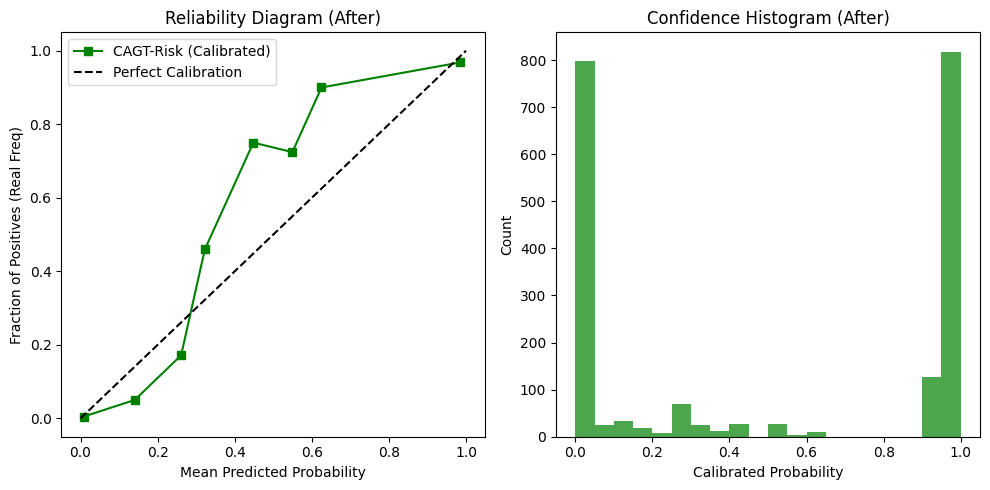

In [4]:
# 1. Fit Isotonic Regressor on VALIDATION SET
calibrator = IsotonicRegression(out_of_bounds='clip')
calibrator.fit(raw_val_probs, y_val)

# 2. Apply Calibrator to TEST SET
calibrated_test_probs = calibrator.predict(raw_test_probs)

brier_post = brier_score_loss(y_test, calibrated_test_probs)
ece_post = compute_ece(y_test, calibrated_test_probs)

print(f"[POST-CALIBRATION] Brier Score: {brier_post:.4f} (Improvement: {brier_pre - brier_post:.4f})")
print(f"[POST-CALIBRATION] Expected Calibration Error: {ece_post:.4f} (Improvement: {ece_pre - ece_post:.4f})")

plt.figure(figsize=(10, 5))

# Reliability Diagram (After)
plt.subplot(1, 2, 1)
prob_true_c, prob_pred_c = calibration_curve(y_test, calibrated_test_probs, n_bins=10)
plt.plot(prob_pred_c, prob_true_c, marker='s', color='green', label='CAGT-Risk (Calibrated)')
plt.plot([0, 1], [0, 1], 'k--', label='Perfect Calibration')
plt.title('Reliability Diagram (After)')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives (Real Freq)')
plt.legend()

# Confidence Histogram (After)
plt.subplot(1, 2, 2)
plt.hist(calibrated_test_probs, bins=20, color='green', alpha=0.7)
plt.title('Confidence Histogram (After)')
plt.xlabel('Calibrated Probability')
plt.ylabel('Count')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'post_calibration.png'))
plt.show()


## 4. Uncertainty vs Error Relationship
Does the model's self-reported uncertainty variance actually correlate with prediction errors? 
We analyze False Alarms and Missed Anomalies.


<Figure size 800x600 with 0 Axes>

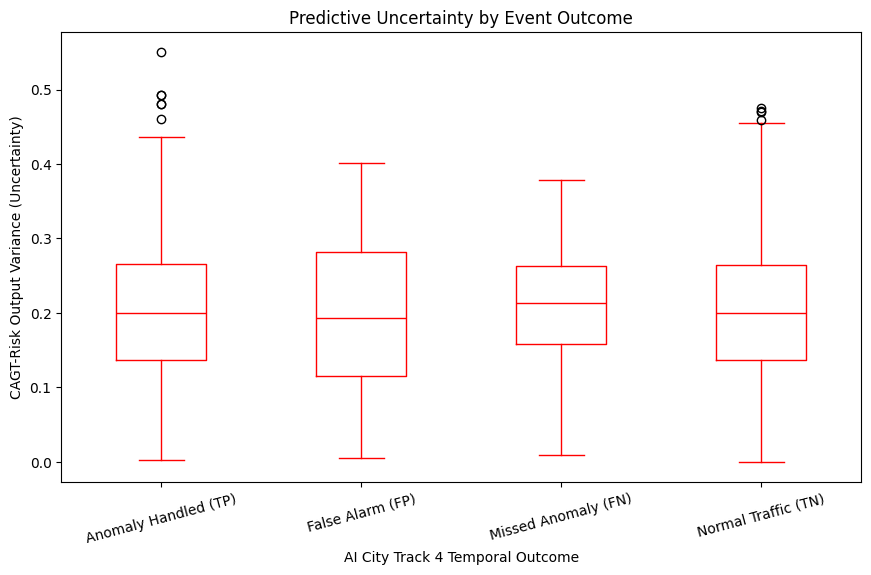

Ideally, 'False Alarms' and 'Missed Anomalies' should exhibit significantly higher model uncertainty than correct predictions.


In [5]:
df_analysis = pd.DataFrame({
    'ground_truth': y_test,
    'calibrated_prob': calibrated_test_probs,
    'uncertainty': test_uncertainty_variance
})

df_analysis['prediction'] = (df_analysis['calibrated_prob'] > 0.5).astype(int)
df_analysis['error'] = np.abs(df_analysis['ground_truth'] - df_analysis['calibrated_prob'])
df_analysis['is_wrong'] = df_analysis['prediction'] != df_analysis['ground_truth']

# Categorize errors
conditions = [
    (df_analysis['ground_truth'] == 0) & (df_analysis['prediction'] == 0), # True Negative
    (df_analysis['ground_truth'] == 1) & (df_analysis['prediction'] == 1), # True Positive
    (df_analysis['ground_truth'] == 0) & (df_analysis['prediction'] == 1), # False Alarm
    (df_analysis['ground_truth'] == 1) & (df_analysis['prediction'] == 0)  # Missed Anomaly
]
choices = ['Normal Traffic (TN)', 'Anomaly Handled (TP)', 'False Alarm (FP)', 'Missed Anomaly (FN)']
df_analysis['outcome_type'] = np.select(conditions, choices, default='Unknown')

plt.figure(figsize=(8, 6))
df_analysis.boxplot(column='uncertainty', by='outcome_type', figsize=(10,6), grid=False, color='red')
plt.title('Predictive Uncertainty by Event Outcome')
plt.suptitle('') # Remove default suptitle
plt.ylabel('CAGT-Risk Output Variance (Uncertainty)')
plt.xlabel('AI City Track 4 Temporal Outcome')
plt.xticks(rotation=15)
plt.savefig(os.path.join(OUTPUT_DIR, 'uncertainty_vs_error.png'))
plt.show()

print("Ideally, 'False Alarms' and 'Missed Anomalies' should exhibit significantly higher model uncertainty than correct predictions.")

# Save calibrated outputs
df_analysis.to_csv(os.path.join(OUTPUT_DIR, 'calibrated_predictions_with_uncertainty.csv'), index=False)
